Creating Figure 2: Velocity...


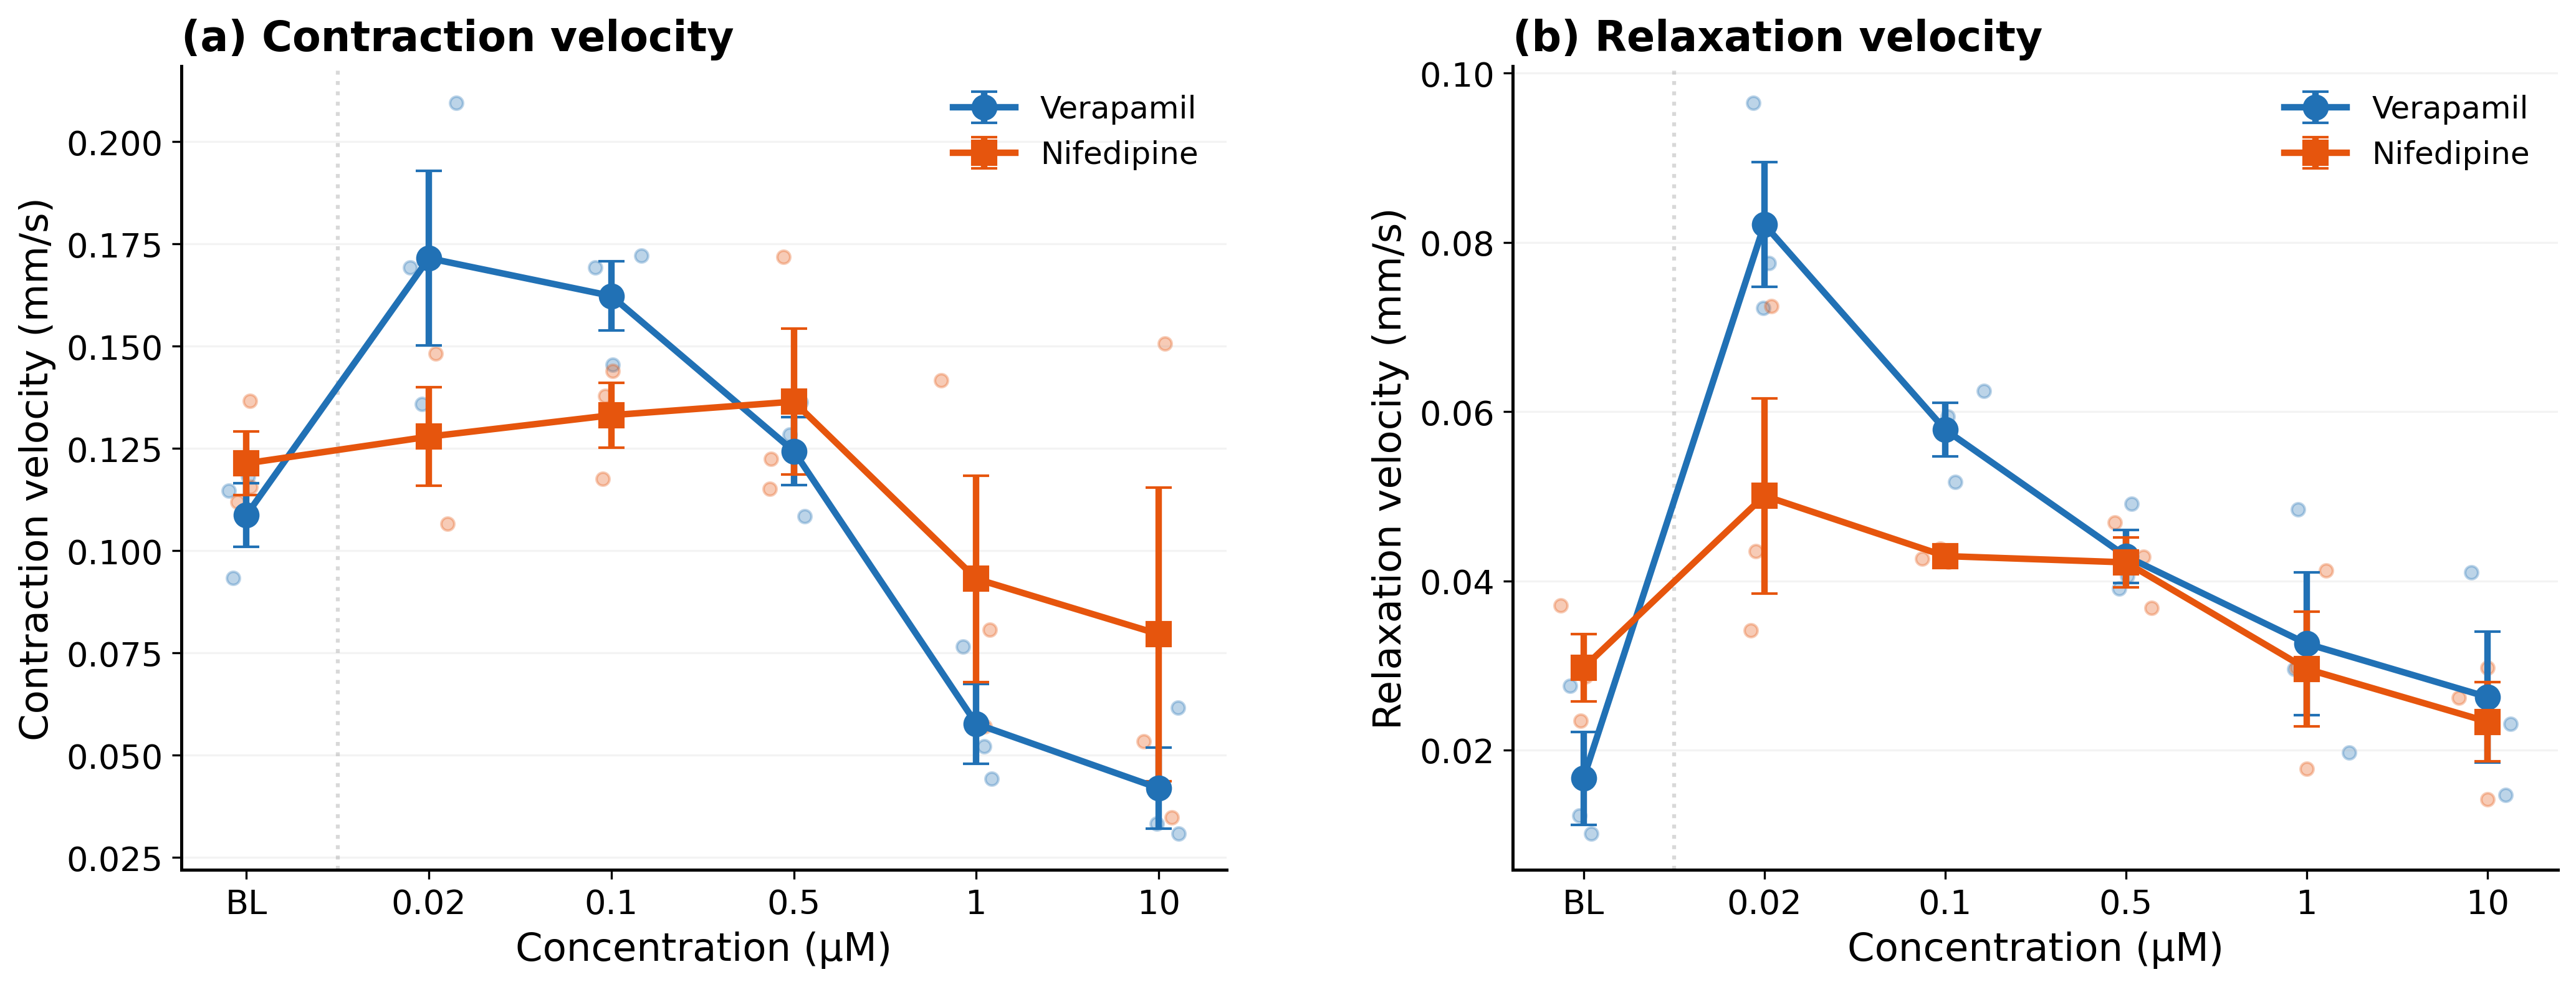


Creating Figure 3: Direction spread vs maturation...


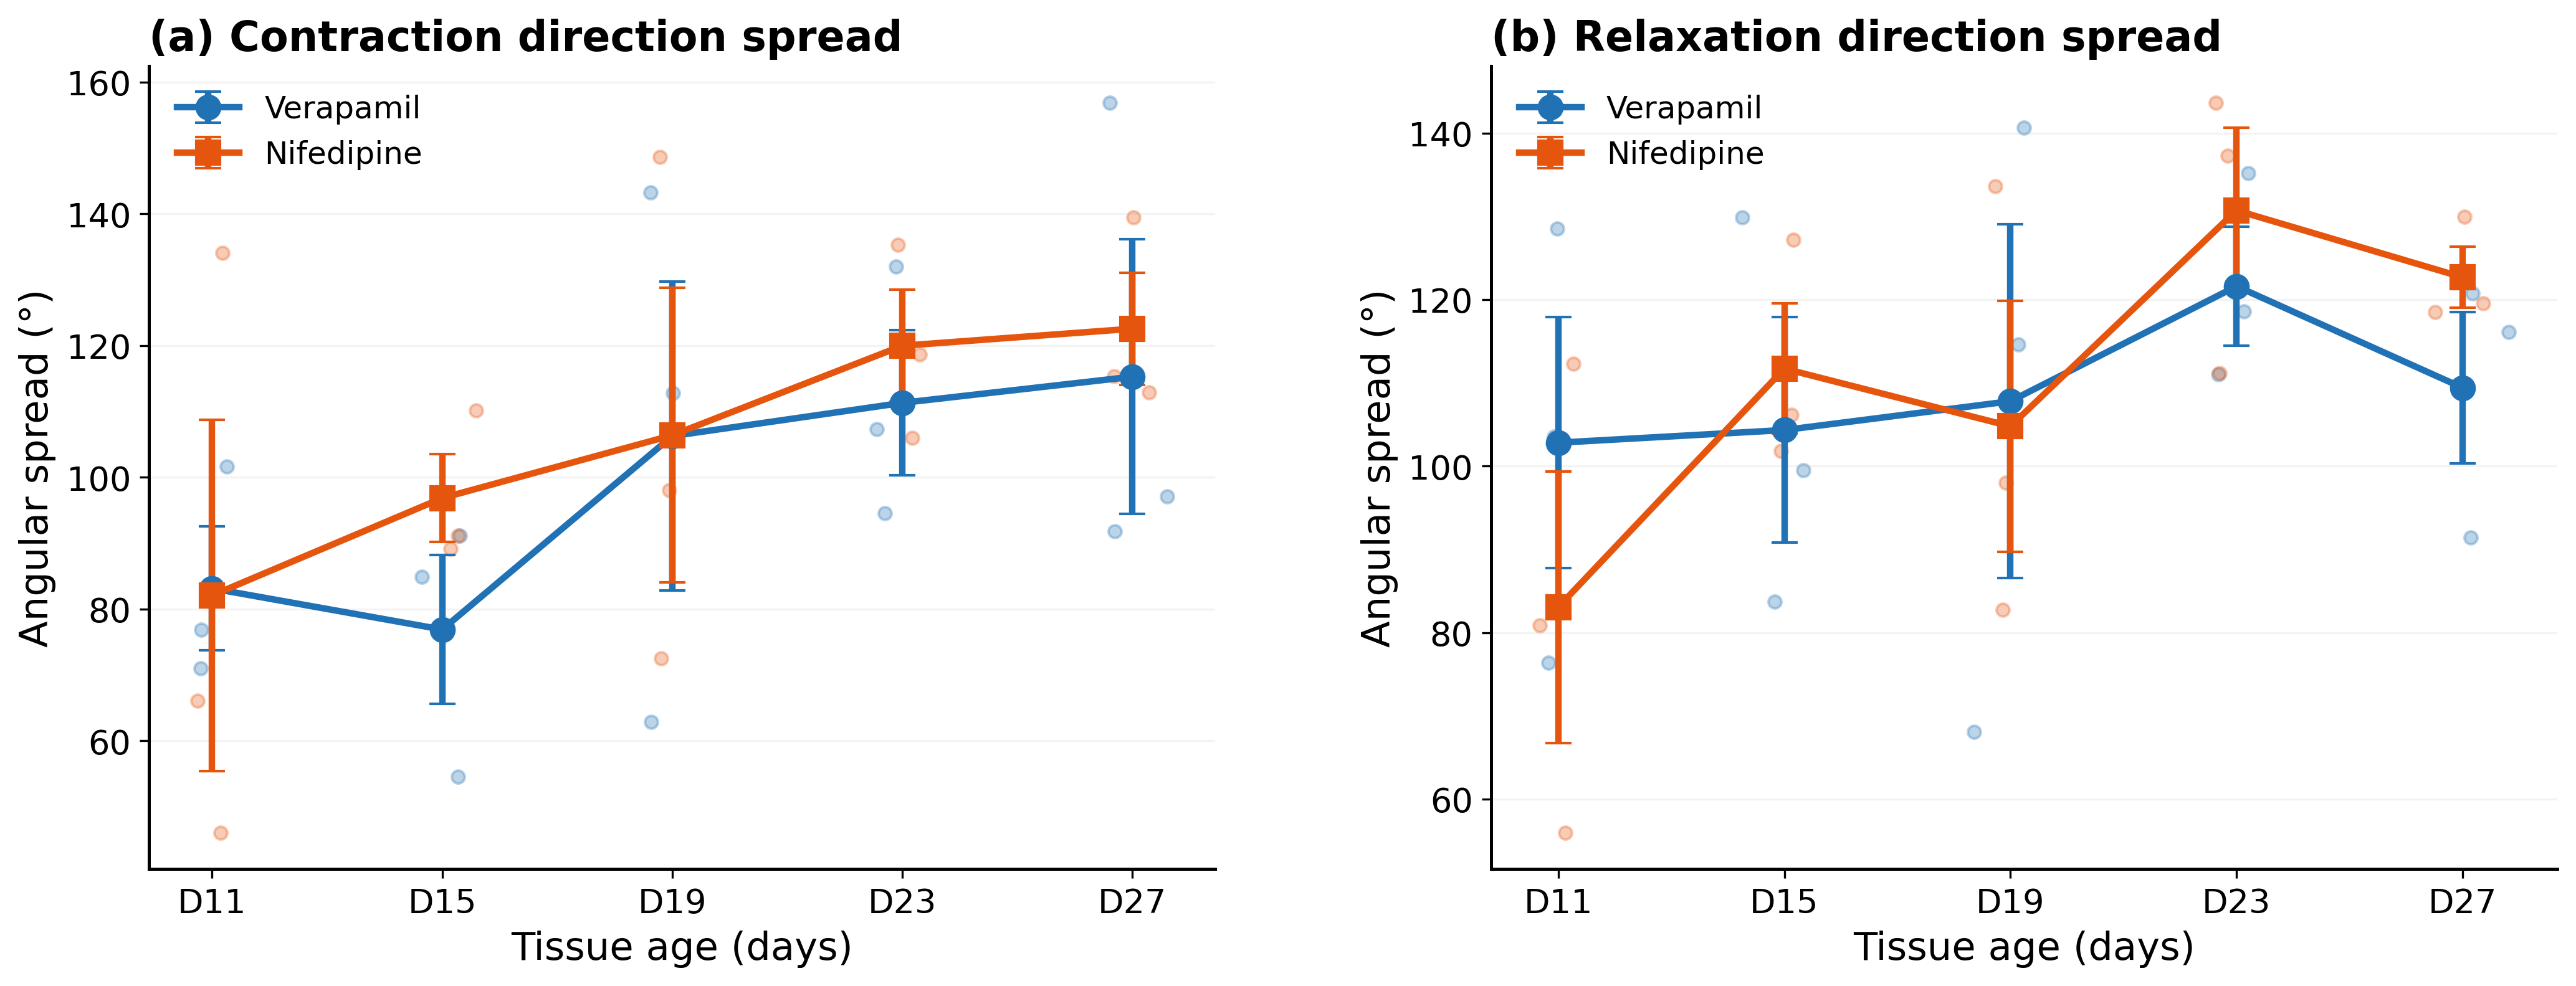


Creating Figure 4: Spatial...


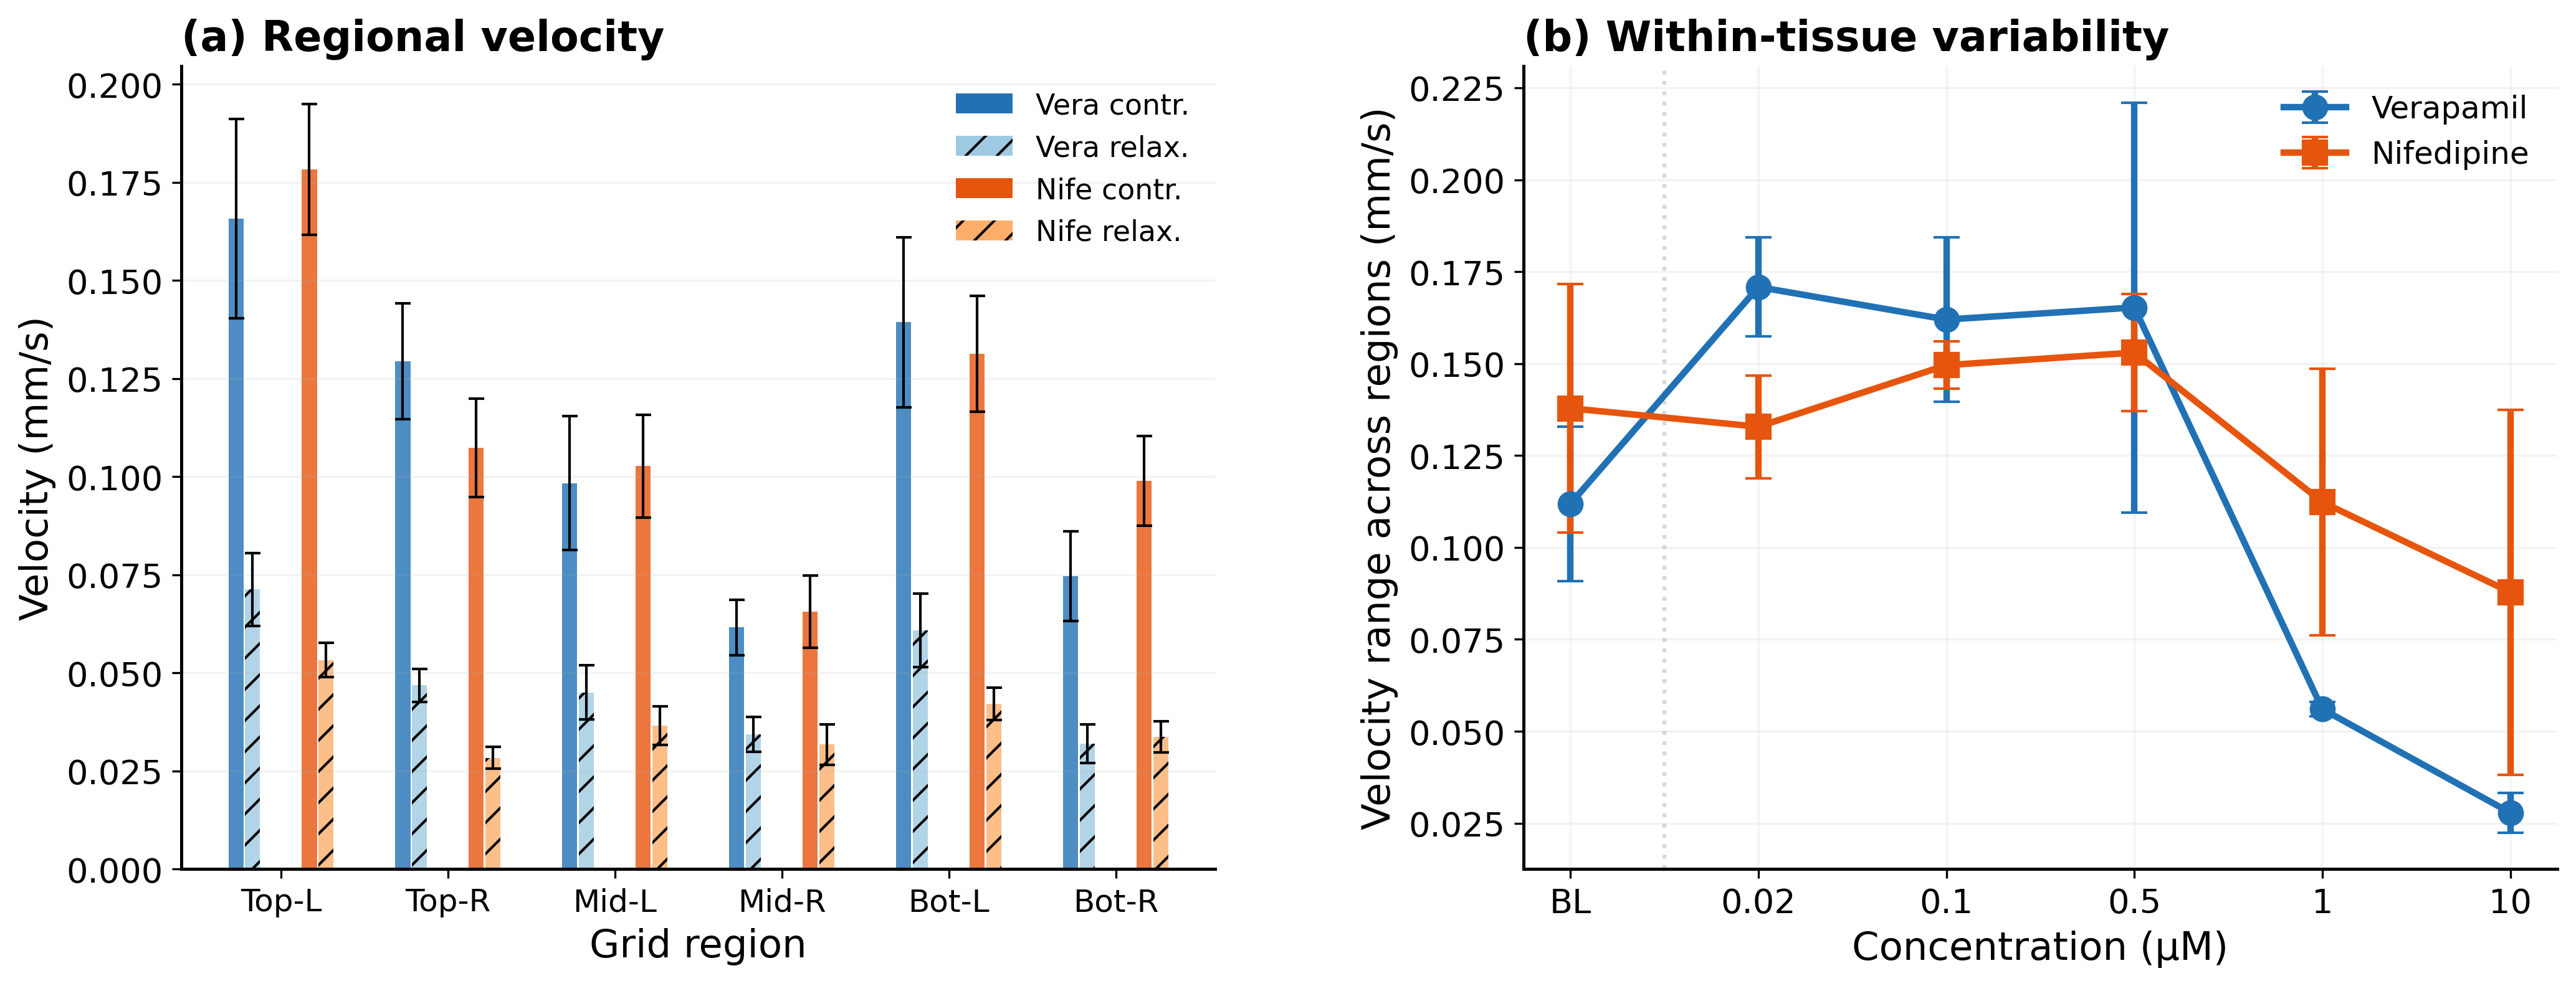


ALL STATS FOR PAPER TEXT

Spearman correlation
  Used for small sample sizes and noisy biological data.
  Tests whether two variables show a consistent increasing
  or decreasing trend, even if the relationship is not linear.

Wilcoxon signed-rank test
  Used for paired two-group comparisons such as rise vs decay.
  Appropriate for small sample sizes and non-normal data.

Kruskal-Wallis test
  Used for comparing three or more independent groups.
  Here, it compares top, middle, and bottom tissue regions.

Slope difference z test
  Used to test whether concentration-response slopes differ
  between verapamil and nifedipine.

how to interprete r (r = correlation coefficient)
  |r| < 0.3   weak 
  0.3~0.5     moderate 
  0.5~0.7     strong 
  >0.7        very strong

Slope difference z test:
Contraction slope diff: p = 0.0093
Relaxation slope diff:  p = 0.0137

Spearman correlation:
  vera Contr vs conc: r = -0.88, p = 0.0000
  vera Relax vs conc: r = -0.87, p = 0.0000
  nife Contr vs co

In [ ]:
#!/usr/bin/env python3
"""
figures for paper
Fig 2 (1×2): Contraction vel vs conc + Relaxation vel vs conc
Fig 3 (1×2): Contraction direction spread vs age + Relaxation direction spread vs age
Fig 4 (1×2): Regional velocity + Variability vs dose
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 14,
    'axes.labelsize': 15,
    'axes.titlesize': 16,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 12,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 1.2,
})

VERA = '#2171B5'
NIFE = '#E6550D'
VERA_LIGHT = '#9ECAE1'
NIFE_LIGHT = '#FDAE6B'

CSV_PATH = "/.../all_results.csv"
df = pd.read_csv(CSV_PATH)

regions = ['r0c0', 'r0c1', 'r1c0', 'r1c1', 'r2c0', 'r2c1']

for phase in ['rise', 'decay']:
    vel_cols = [f"r{r}c{c}_{phase}_vel_mm_s" for r in range(3) for c in range(2)]
    vel_cols = [c for c in vel_cols if c in df.columns]
    df[f'mean_{phase}_vel'] = df[vel_cols].mean(axis=1)
    vals = df[vel_cols]
    df[f'{phase}_vel_range'] = vals.max(axis=1) - vals.min(axis=1)

df['vel_ratio'] = df['mean_rise_vel'] / df['mean_decay_vel'].replace(0, np.nan)

# Direction spread
def circ_std_deg(angles_deg):
    angles_deg = np.array(angles_deg, dtype=np.float64)
    rad = np.radians(angles_deg)
    R = np.sqrt(np.nanmean(np.cos(rad))**2 + np.nanmean(np.sin(rad))**2)
    if R > 1: R = 1.0
    if R < 1e-10: return 180.0
    return np.degrees(np.sqrt(-2 * np.log(R)))

for phase in ['rise', 'decay']:
    angle_cols = [f"{r}_{phase}_angle" for r in regions if f"{r}_{phase}_angle" in df.columns]
    if angle_cols:
        spreads = []
        for _, row in df.iterrows():
            vals = row[angle_cols].dropna().values
            vals = np.array(vals, dtype=np.float64)
            spreads.append(circ_std_deg(vals) if len(vals) >= 2 else np.nan)
        df[f'{phase}_angle_spread'] = spreads

df_conc = df[(df['conc'].notna()) & (df['conc'] > 0)].copy()
df_baseline = df[df['conc'] == 0].copy()
df_bl_V = df_baseline[df_baseline['case_name'].str.startswith('V')]
df_bl_N = df_baseline[df_baseline['case_name'].str.startswith('N')]
df_age = df[df['age'].notna()].copy()

conc_labels = ['BL', '0.02', '0.1', '0.5', '1', '10']
conc_values = [0.02, 0.1, 0.5, 1.0, 10.0]
ages = sorted(df_age['age'].unique())
age_labels = [f'D{int(a)}' for a in ages]


# ═══════════════════════════════════
# Helpers
# ═══════════════════════════════════
def dose_plot(ax, col, ylabel, show_legend=False):
    for drug, color, marker, bl_df in [
        ('verapamil', VERA, 'o', df_bl_V),
        ('nifedipine', NIFE, 's', df_bl_N),
    ]:
        sub = df_conc[df_conc['drug'] == drug]
        all_means, all_sems, all_x = [], [], []

        bl_vals = bl_df[col].dropna()
        if len(bl_vals) > 0:
            all_x.append(0)
            all_means.append(bl_vals.mean())
            all_sems.append(bl_vals.std() / np.sqrt(len(bl_vals)) if len(bl_vals) > 1 else 0)
            jitter = np.random.normal(0, 0.08, len(bl_vals))
            ax.scatter(np.zeros(len(bl_vals)) + jitter, bl_vals,
                       color=color, alpha=0.3, s=25, zorder=1)

        for i, c in enumerate(conc_values):
            vals = sub[sub['conc'] == c][col].dropna()
            if len(vals) > 0:
                all_x.append(i + 1)
                all_means.append(vals.mean())
                all_sems.append(vals.std() / np.sqrt(len(vals)) if len(vals) > 1 else 0)
                jitter = np.random.normal(0, 0.08, len(vals))
                ax.scatter(np.full(len(vals), i + 1) + jitter, vals,
                           color=color, alpha=0.3, s=25, zorder=1)

        ax.errorbar(all_x, all_means, yerr=all_sems,
                    marker=marker, color=color, capsize=5, linewidth=2.5,
                    markersize=9, label=drug.capitalize(), zorder=3)

    ax.set_xticks(range(len(conc_labels)))
    ax.set_xticklabels(conc_labels)
    ax.set_xlabel('Concentration (μM)')
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.15, axis='y')
    ax.axvline(0.5, color='gray', linestyle=':', alpha=0.3)
    if show_legend:
        ax.legend(frameon=False, loc='best')


def age_plot(ax, col, ylabel, show_legend=False):
    age_x = np.arange(len(ages))
    for drug, color, marker in [('verapamil', VERA, 'o'), ('nifedipine', NIFE, 's')]:
        sub = df_age[df_age['drug'] == drug]
        means, sems = [], []
        for age in ages:
            vals = sub[sub['age'] == age][col].dropna()
            means.append(vals.mean() if len(vals) > 0 else np.nan)
            sems.append(vals.std() / np.sqrt(len(vals)) if len(vals) > 1 else 0)
        ax.errorbar(age_x, means, yerr=sems,
                    marker=marker, color=color, capsize=5, linewidth=2.5,
                    markersize=9, label=drug.capitalize(), zorder=3)
        for i, age in enumerate(ages):
            pts = sub[sub['age'] == age][col].dropna()
            jitter = np.random.normal(0, 0.08, len(pts))
            ax.scatter(np.full(len(pts), i) + jitter, pts,
                       color=color, alpha=0.3, s=25, zorder=1)
    ax.set_xticks(age_x)
    ax.set_xticklabels(age_labels)
    ax.set_xlabel('Tissue age (days)')
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.15, axis='y')
    if show_legend:
        ax.legend(frameon=False, loc='best')


# ═══════════════════════════════════════════════
#  FIGURE 2: VELOCITY 1×2
# ═══════════════════════════════════════════════
print("Creating Figure 2: Velocity...")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Contraction vel vs conc
ax = axes[0]
dose_plot(ax, 'mean_rise_vel', 'Contraction velocity (mm/s)', show_legend=True)
ax.set_title('(a) Contraction velocity', loc='left', fontweight='bold')

# compute slope diff for printing
v_sub = df_conc[df_conc['drug'] == 'verapamil'].dropna(subset=['mean_rise_vel'])
n_sub = df_conc[df_conc['drug'] == 'nifedipine'].dropna(subset=['mean_rise_vel'])
sv, _, _, _, sev = stats.linregress(np.log10(v_sub['conc']), v_sub['mean_rise_vel'])
sn, _, _, _, sen = stats.linregress(np.log10(n_sub['conc']), n_sub['mean_rise_vel'])
z = (sv - sn) / np.sqrt(sev**2 + sen**2)
p_diff_contr = 2 * (1 - stats.norm.cdf(abs(z)))

# (b) Relaxation vel vs conc
ax = axes[1]
dose_plot(ax, 'mean_decay_vel', 'Relaxation velocity (mm/s)', show_legend=True)
ax.set_title('(b) Relaxation velocity', loc='left', fontweight='bold')

v_sub = df_conc[df_conc['drug'] == 'verapamil'].dropna(subset=['mean_decay_vel'])
n_sub = df_conc[df_conc['drug'] == 'nifedipine'].dropna(subset=['mean_decay_vel'])
sv, _, _, _, sev = stats.linregress(np.log10(v_sub['conc']), v_sub['mean_decay_vel'])
sn, _, _, _, sen = stats.linregress(np.log10(n_sub['conc']), n_sub['mean_decay_vel'])
z = (sv - sn) / np.sqrt(sev**2 + sen**2)
p_diff_relax = 2 * (1 - stats.norm.cdf(abs(z)))

plt.tight_layout(w_pad=4)
#plt.savefig("fig2_velocity.png", dpi=300)
#plt.savefig("fig2_velocity.pdf")
plt.show()
#print(f"Saved fig2. slope diff contr p={p_diff_contr:.4f}, relax p={p_diff_relax:.4f}")


# ═══════════════════════════════════════════════
#  FIGURE 3: DIRECTION SPREAD vs AGE 1×2
# ═══════════════════════════════════════════════
print("\nCreating Figure 3: Direction spread vs maturation...")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Contraction direction spread vs age
ax = axes[0]
age_plot(ax, 'rise_angle_spread', 'Angular spread (°)', show_legend=True)
ax.set_title('(a) Contraction direction spread', loc='left', fontweight='bold')

# (b) Relaxation direction spread vs age
ax = axes[1]
age_plot(ax, 'decay_angle_spread', 'Angular spread (°)', show_legend=True)
ax.set_title('(b) Relaxation direction spread', loc='left', fontweight='bold')

plt.tight_layout(w_pad=4)
#plt.savefig("fig3_direction_spread.png", dpi=300)
#plt.savefig("fig3_direction_spread.pdf")
plt.show()
#print("Saved fig3.")


# ═══════════════════════════════════════════════
#  FIGURE 4: SPATIAL 1×2
# ═══════════════════════════════════════════════
print("\nCreating Figure 4: Spatial...")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Regional velocity by drug
ax = axes[0]
region_names_short = ['Top-L', 'Top-R', 'Mid-L', 'Mid-R', 'Bot-L', 'Bot-R']
region_codes = ['r0c0', 'r0c1', 'r1c0', 'r1c1', 'r2c0', 'r2c1']
x = np.arange(len(region_codes))

for drug_idx, (drug, color_rise, color_decay) in enumerate([
    ('verapamil', VERA, VERA_LIGHT),
    ('nifedipine', NIFE, NIFE_LIGHT),
]):
    sub = df_conc[df_conc['drug'] == drug]
    offset = -0.22 if drug_idx == 0 else 0.22
    for phase, color, hatch in [('rise', color_rise, None), ('decay', color_decay, '//')]:
        means, sems = [], []
        for rc in region_codes:
            col = f"{rc}_{phase}_vel_mm_s"
            if col in sub.columns:
                vals = sub[col].dropna()
                means.append(vals.mean())
                sems.append(vals.std() / np.sqrt(len(vals)) if len(vals) > 1 else 0)
            else:
                means.append(0); sems.append(0)
        phase_offset = -0.05 if phase == 'rise' else 0.05
        ax.bar(x + offset + phase_offset, means, width=0.09, yerr=sems,
               capsize=3, color=color, alpha=0.8, hatch=hatch,
               error_kw={'linewidth': 1})

ax.set_xticks(x)
ax.set_xticklabels(region_names_short, fontsize=12)
ax.set_xlabel('Grid region')
ax.set_ylabel('Velocity (mm/s)')
ax.set_title('(a) Regional velocity', loc='left', fontweight='bold')

legend_elements = [
    Patch(facecolor=VERA, label='Vera contr.'),
    Patch(facecolor=VERA_LIGHT, hatch='//', label='Vera relax.'),
    Patch(facecolor=NIFE, label='Nife contr.'),
    Patch(facecolor=NIFE_LIGHT, hatch='//', label='Nife relax.'),
]
ax.legend(handles=legend_elements, frameon=False, fontsize=11, loc='upper right')
ax.grid(True, alpha=0.15, axis='y')

# (b) Within-tissue variability vs dose
ax = axes[1]
for drug, color, marker, bl_df in [
    ('verapamil', VERA, 'o', df_bl_V),
    ('nifedipine', NIFE, 's', df_bl_N),
]:
    sub = df_conc[df_conc['drug'] == drug].dropna(subset=['rise_vel_range'])
    all_x, all_means, all_sems = [], [], []

    bl_vals = bl_df['rise_vel_range'].dropna() if 'rise_vel_range' in bl_df.columns else pd.Series()
    if len(bl_vals) > 0:
        all_x.append(0)
        all_means.append(bl_vals.mean())
        all_sems.append(bl_vals.std() / np.sqrt(len(bl_vals)) if len(bl_vals) > 1 else 0)

    for i, c in enumerate(conc_values):
        vals = sub[sub['conc'] == c]['rise_vel_range'].dropna()
        if len(vals) > 0:
            all_x.append(i + 1)
            all_means.append(vals.mean())
            all_sems.append(vals.std() / np.sqrt(len(vals)) if len(vals) > 1 else 0)

    ax.errorbar(all_x, all_means, yerr=all_sems,
                marker=marker, color=color, capsize=5, linewidth=2.5,
                markersize=9, label=drug.capitalize())

ax.set_xticks(range(len(conc_labels)))
ax.set_xticklabels(conc_labels)
ax.axvline(0.5, color='gray', linestyle=':', alpha=0.3)
ax.set_xlabel('Concentration (μM)')
ax.set_ylabel('Velocity range across regions (mm/s)')
ax.set_title('(b) Within-tissue variability', loc='left', fontweight='bold')
ax.legend(frameon=False)
ax.grid(True, alpha=0.15)

plt.tight_layout(w_pad=4)
#plt.savefig("fig4_spatial.png", dpi=300)
#plt.savefig("fig4_spatial.pdf")
plt.show()
#print("Saved fig4.")



# ═══════════════════════════════════════════════
# Print all stats for paper text
# ═══════════════════════════════════════════════
print("\n" + "=" * 60)
print("ALL STATS FOR PAPER TEXT")
print("=" * 60)

print("\nSpearman correlation")
print("  Used for small sample sizes and noisy biological data.")
print("  Tests whether two variables show a consistent increasing")
print("  or decreasing trend, even if the relationship is not linear.")

print("\nWilcoxon signed-rank test")
print("  Used for paired two-group comparisons such as rise vs decay.")
print("  Appropriate for small sample sizes and non-normal data.")

print("\nKruskal-Wallis test")
print("  Used for comparing three or more independent groups.")
print("  Here, it compares top, middle, and bottom tissue regions.")

print("\nSlope difference z test")
print("  Used to test whether concentration-response slopes differ")
print("  between verapamil and nifedipine.")

# r interpretation
print("\nhow to interprete r (r = correlation coefficient)")
print("  |r| < 0.3   weak \n  0.3~0.5     moderate \n  0.5~0.7     strong \n  >0.7        very strong")


# Velocity slope difference
print("\nSlope difference z test:")
print(f"Contraction slope diff: p = {p_diff_contr:.4f}")
print(f"Relaxation slope diff:  p = {p_diff_relax:.4f}")


# Velocity vs concentration
print("\nSpearman correlation:")
for drug in ['verapamil', 'nifedipine']:
    for col, label in [('mean_rise_vel', 'Contr'), ('mean_decay_vel', 'Relax')]:
        sub = df_conc[df_conc['drug'] == drug].dropna(subset=[col])
        _, _, r_val, p_val, _ = stats.linregress(np.log10(sub['conc']), sub[col])
        print(f"  {drug[:4]} {label} vs conc: r = {r_val:.2f}, p = {p_val:.4f}")

# Direction spread vs age
print("\nSpearman correlation:")
for phase, label in [('rise', 'Contraction'), ('decay', 'Relaxation')]:
    col = f'{phase}_angle_spread'
    # Overall
    valid = df_age[['age', col]].dropna()
    if len(valid) >= 4:
        r, p = stats.spearmanr(valid['age'], valid[col])
        print(f"  {label} spread vs age (overall): r = {r:.2f}, p = {p:.3f}")
    # Per drug
    for drug in ['verapamil', 'nifedipine']:
        sub = df_age[df_age['drug'] == drug][['age', col]].dropna()
        if len(sub) >= 4:
            r, p = stats.spearmanr(sub['age'], sub[col])
            print(f"  {label} spread vs age ({drug[:4]}): r = {r:.2f}, p = {p:.3f}")


# Regional comparison
print("\nKruskal Wallis test:")
rise_top = df_conc[['r0c0_rise_vel_mm_s', 'r0c1_rise_vel_mm_s']].mean(axis=1)
rise_mid = df_conc[['r1c0_rise_vel_mm_s', 'r1c1_rise_vel_mm_s']].mean(axis=1)
rise_bot = df_conc[['r2c0_rise_vel_mm_s', 'r2c1_rise_vel_mm_s']].mean(axis=1)
_, p_reg = stats.kruskal(rise_top.dropna(), rise_mid.dropna(), rise_bot.dropna())
print(f"  Regional Kruskal: p = {p_reg:.1e}")

# Variability vs dose
print("\nSpearman correlation:")
for drug in ['verapamil', 'nifedipine']:
    sub = df_conc[df_conc['drug'] == drug].dropna(subset=['rise_vel_range'])
    r_sp, p_sp = stats.spearmanr(np.log10(sub['conc']), sub['rise_vel_range'])
    print(f"  {drug[:4]} variability vs dose: r = {r_sp:.2f}, p = {p_sp:.4f}")

# Velocity ratio
median_ratio = df_conc['vel_ratio'].median()
print("\nDescriptive statistic:")
print(f"  Median velocity ratio: {median_ratio:.2f}x")

print("\nDescriptive statistic:")
print(f"  Median velocity ratio: {median_ratio:.1f}x")

# Rise vs decay
_, p_wr = stats.wilcoxon(df_conc['mean_rise_vel'], df_conc['mean_decay_vel'])
print("\nWilcoxon signed-rank test:")
print(f"  Rise > Decay Wilcoxon: p = {p_wr:.1e}")

# Velocity vs age
print("\nSpearman correlation:")
for drug in ['verapamil', 'nifedipine']:
    for col, label in [('mean_rise_vel', 'Contr'), ('mean_decay_vel', 'Relax')]:
        sub = df_age[df_age['drug'] == drug][['age', col]].dropna()
        if len(sub) >= 4:
            r, p = stats.spearmanr(sub['age'], sub[col])
            print(f"  {drug[:4]} {label} vs age: r = {r:.2f}, p = {p:.3f}")

In [ ]:
import pandas as pd, numpy as np
df = pd.read_csv("/.../all_results_rebuttal.csv")

print("no spatial division - 1 x 1 : B and D analysis ")
print(" ")
print(f"n cases: {len(df)}")
print(f"\nSpatial vel loss (rise):  {df['abl_spatial_loss_rise'].mean()*100:.1f}% ± {df['abl_spatial_loss_rise'].std()*100:.1f}%")
print(f"Spatial vel loss (decay): {df['abl_spatial_loss_decay'].mean()*100:.1f}% ± {df['abl_spatial_loss_decay'].std()*100:.1f}%")
print(f"Phase asymmetry vel:  {df['abl_phase_asymmetry_vel'].median():.2f}× (median)")
print(f"Total loss vel:       {df['abl_total_loss_vel'].mean()*100:.1f}% ± {df['abl_total_loss_vel'].std()*100:.1f}%")

no spatial division - 1 x 1 : B and D analysis 
 
n cases: 66

Spatial vel loss (rise):  46.2% ± 19.2%
Spatial vel loss (decay): 52.2% ± 18.5%
Phase asymmetry vel:  2.52× (median)
Total loss vel:       90.9% ± 4.0%


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

df = pd.read_csv("/.../all_results_rebuttal.csv")
print(f"n cases: {len(df)}\n")

# ============================================================
# (1) PHASE ABLATION (E vs C)
# ============================================================
print("="*78)
print("PHASE ABLATION  (E vs C, both 3x2)")
print("="*78)

df['phase_collapse_vs_rise']  = df['abl_C_full_vel'] / df['abl_E_rise_vel']
df['phase_collapse_vs_decay'] = df['abl_C_full_vel'] / df['abl_E_decay_vel']
df['phase_collapse_disp']     = df['abl_C_full_disp'] / df['abl_E_rise_disp']

print(f"\n[Magnitude collapse]")
print(f"  C_full_vel / E_rise_vel  = {df['phase_collapse_vs_rise'].mean()*100:.1f}% ± {df['phase_collapse_vs_rise'].std()*100:.1f}%")
print(f"  C_full_vel / E_decay_vel = {df['phase_collapse_vs_decay'].mean()*100:.1f}% ± {df['phase_collapse_vs_decay'].std()*100:.1f}%")
print(f"  C_full_disp / E_rise_disp = {df['phase_collapse_disp'].mean()*100:.1f}% ± {df['phase_collapse_disp'].std()*100:.1f}%")

# compare R
print(f"\n[Direction consistency R]")
print(f"  E (3x2 + phase):  R = {df['abl_E_R_mean'].mean():.3f} ± {df['abl_E_R_mean'].std():.3f}")
print(f"  C (3x2 + nophase): R = {df['abl_C_R_mean'].mean():.3f} ± {df['abl_C_R_mean'].std():.3f}")
df['R_drop_phase'] = df['abl_E_R_mean'] - df['abl_C_R_mean']
print(f"  → R drop: {df['R_drop_phase'].mean():.3f} ± {df['R_drop_phase'].std():.3f}")
# get p-val by Wilcoxon)
t_stat, p_val = stats.wilcoxon(df['abl_E_R_mean'], df['abl_C_R_mean'])
print(f"  Wilcoxon paired test: p = {p_val:.2e}")

# ============================================================
# (2) ALL CONFIGS R COMPARISON
# ============================================================
print("\n" + "="*78)
print("DIRECTION CONSISTENCY R — all 4 configs")
print("="*78)
for col, label in [
    ('abl_E_R_mean', 'E (3x2 + phase)   [PROPOSED]'),
    ('abl_C_R_mean', 'C (3x2 + nophase)'),
    ('abl_D_R_mean', 'D (1x1 + phase)'),
    ('abl_B_R_mean', 'B (1x1 + nophase) [global]'),
]:
    print(f"  {label:<32} R = {df[col].mean():.3f} ± {df[col].std():.3f}")

# ============================================================
# (3) PAIRED STATISTICAL TESTS for rebuttal
# ============================================================
print("\n" + "="*78)
print("STATISTICAL TESTS for rebuttal")
print("="*78)

# E vs D (spatial value)
e_rise = df['abl_E_rise_disp'].dropna()
d_rise = df['abl_D_rise_disp'].dropna()
common = df.dropna(subset=['abl_E_rise_disp', 'abl_D_rise_disp'])
t, p = stats.wilcoxon(common['abl_E_rise_disp'], common['abl_D_rise_disp'])
print(f"\n  Spatial split value (E vs D, rise):")
print(f"    Wilcoxon p = {p:.2e}, n = {len(common)}")

# Phase asymmetry significance (rise vs decay vel)
common = df.dropna(subset=['abl_E_rise_vel', 'abl_E_decay_vel'])
t, p = stats.wilcoxon(common['abl_E_rise_vel'], common['abl_E_decay_vel'])
print(f"\n  Phase asymmetry (E_rise vel vs E_decay vel):")
print(f"    Wilcoxon p = {p:.2e}, median ratio = {(common['abl_E_rise_vel']/common['abl_E_decay_vel']).median():.2f}×")

# ============================================================
# (4) RANGE OF CASE-LEVEL EFFECTS
# ============================================================
print("\n" + "="*78)
print("RANGE OF CASE-LEVEL EFFECTS  (min / median / max)")
print("="*78)
for metric, label in [
    ('abl_total_loss_vel',    'Spatial Total loss vel (D vs E)'),
]:
    d = df[metric].dropna()
    if 'loss' in metric:
        print(f"  {label:<22}  min={d.min()*100:5.1f}%  median={d.median()*100:5.1f}%  max={d.max()*100:5.1f}%")
    else:
        print(f"  {label:<22}  min={d.min():5.2f}×  median={d.median():5.2f}×  max={d.max():5.2f}×")

n cases: 66

PHASE ABLATION  (E vs C, both 3x2)

[Magnitude collapse]
  C_full_vel / E_rise_vel  = 17.4% ± 7.3%
  C_full_vel / E_decay_vel = 45.5% ± 19.5%
  C_full_disp / E_rise_disp = 58.3% ± 18.9%

[Direction consistency R]
  E (3x2 + phase):  R = 0.835 ± 0.191
  C (3x2 + nophase): R = 0.365 ± 0.209
  → R drop: 0.470 ± 0.195
  Wilcoxon paired test: p = 1.72e-12

DIRECTION CONSISTENCY R — all 4 configs
  E (3x2 + phase)   [PROPOSED]     R = 0.835 ± 0.191
  C (3x2 + nophase)                R = 0.365 ± 0.209
  D (1x1 + phase)                  R = 0.824 ± 0.198
  B (1x1 + nophase) [global]       R = 0.377 ± 0.234

STATISTICAL TESTS for rebuttal

  Spatial split value (E vs D, rise):
    Wilcoxon p = 1.64e-12, n = 66

  Phase asymmetry (E_rise vel vs E_decay vel):
    Wilcoxon p = 1.64e-12, median ratio = 2.52×

RANGE OF CASE-LEVEL EFFECTS  (min / median / max)
  Spatial Total loss vel (D vs E)  min= 79.3%  median= 92.2%  max= 96.8%
